In [33]:
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
import pandas as pd

In [34]:
iris = load_iris()

In [35]:
X = iris.data
y = iris.target

In [36]:

X.shape

(150, 4)

<Axes: >

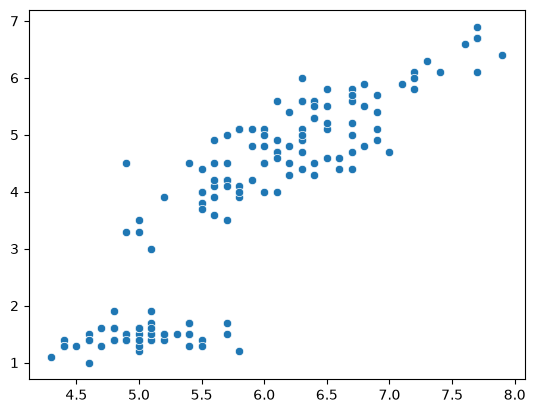

In [37]:
# Visualize
sns.scatterplot(x=X[:, 0], y=X[:, 2])

In [38]:
# scalling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [49]:
# Optional - dimensionality reduction using PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

pca_data = pca.fit_transform(X_scaled)

In [50]:
# warning hide
import warnings

warnings.filterwarnings(
    "ignore",
    message="KMeans is known to have a memory leak"
)

In [51]:
# Elbow method
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(pca_data)
    wcss.append(kmeans.inertia_)

In [52]:
wcss

[574.8792432000103,
 197.40381604541284,
 115.02075663594012,
 89.56358397321243,
 81.90292105464194,
 58.72762636907879,
 48.4032985283178,
 42.022865310144674,
 37.13729807932522,
 38.44868326402656]

<Axes: >

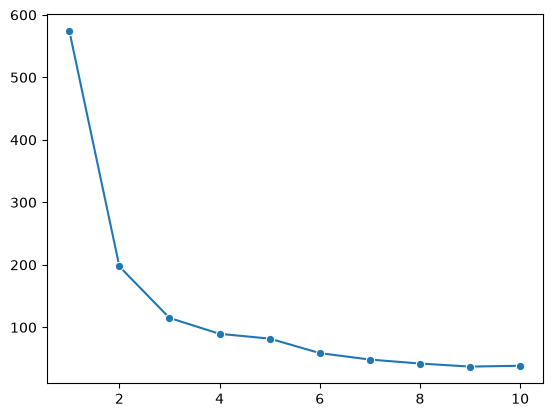

In [53]:
sns.lineplot(x=range(1, 11), y=wcss, marker='o')

<Axes: >

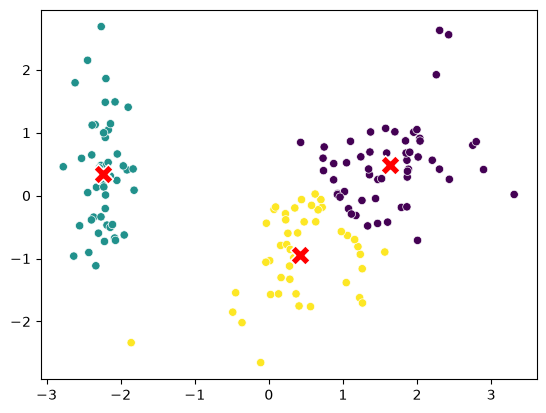

In [59]:
# KMeans

kmeans = KMeans(n_clusters=3, random_state=10)
labels = kmeans.fit_predict(pca_data)

sns.scatterplot(x=pca_data[:, 0], y=pca_data[:, 1], c=labels)
sns.scatterplot(x=kmeans.cluster_centers_[:, 0], y=kmeans.cluster_centers_[:, 1], marker="X", c="red", s=200)